In [19]:
import matplotlib.pyplot as plt

import torch
import torch.optim as optim
import torch.nn as nn
from torchvision import datasets, transforms
import imageio
from torch.utils.data import random_split

Problem 1A

In [20]:
data_path = '../ecgr4181_HW7/data'

cifar10 = datasets.CIFAR10(root=data_path, train=True, download=True)

n_cifar10  = datasets.CIFAR10(data_path, train=True, download=True, transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),(0.2470, 0.2435, 0.2616))
]))

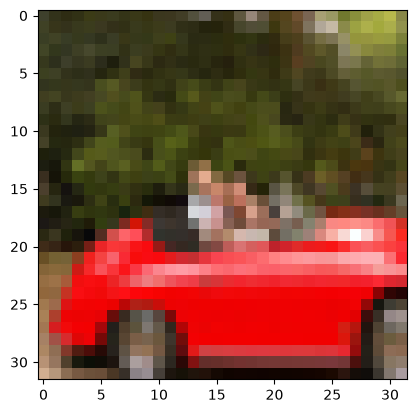

In [21]:
plt.imshow(cifar10[99][0])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9802876..2.1264887].


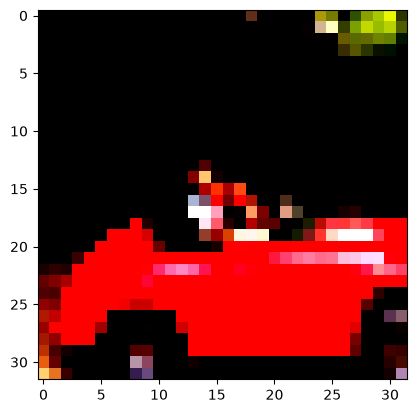

In [22]:
plt.imshow(n_cifar10[99][0].permute(1, 2, 0))

In [23]:
loss_fn = nn.CrossEntropyLoss()

def train_test(model, optimizer, epochs, cifar10):
    train_set, val_set = random_split(cifar10, [int(len(cifar10)*0.8), len(cifar10) - int(len(cifar10)*0.8)])

    train_loader = torch.utils.data.DataLoader(train_set, batch_size=256, shuffle=True)
    c_correct = 0
    c_total = 0

    v_correct = 0
    v_total = 0

    val_loader = torch.utils.data.DataLoader(val_set, batch_size=256, shuffle=False)

    train_loss = []
    val_loss = []

    for epoch in range(epochs):
        for imgs, labels in train_loader:
            imgs = imgs.to("mps")
            labels = labels.to("mps")
            batch_size = imgs.shape[0]
            outputs = model(imgs.flatten(1))
            loss =loss_fn(outputs, labels)

            _, predicted = torch.max(outputs, dim=1)
            c_total += labels.shape[0]
            c_correct += int((predicted == labels).sum())

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        if epoch % 10 == 9 or epoch == 0:
            with torch.no_grad():
                for imgs, labels in val_loader:
                    imgs = imgs.to("mps")
                    labels = labels.to("mps")
                    outputs = model(imgs.flatten(1))
                    _, predicted = torch.max(outputs, dim=1)
                    v_total += labels.shape[0]
                    v_correct += int((predicted == labels).sum())
            train_loss.append(c_correct / c_total)
            val_loss.append(v_correct / v_total)
            print(f"Training Epoch {epoch+1}, Loss: {loss.item()}")
            #print(f"Training Accuracy: {c_correct / c_total:.2f}")
            #print(f"Validation Accuracy: {v_correct / v_total:.2f}")
    plt.plot(train_loss, label='Training Accuracy')
    plt.plot(val_loss, label='Validation Accuracy')
    plt.xlabel('Epochs (x10)')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy over Epochs')
    plt.legend()
    return train_loss, val_loss

Training Epoch 1, Loss: 1.4490554332733154
Training Epoch 10, Loss: 0.7890210151672363
Training Epoch 20, Loss: 0.4011152684688568
Training Epoch 30, Loss: 0.1963389813899994
Training Epoch 40, Loss: 0.09639987349510193
Training Epoch 50, Loss: 0.025487732142210007
Training Epoch 60, Loss: 0.2967184782028198
Training Epoch 70, Loss: 0.1378447562456131
Training Epoch 80, Loss: 0.14550641179084778
Training Epoch 90, Loss: 0.11818522214889526
Training Epoch 100, Loss: 0.09563977271318436


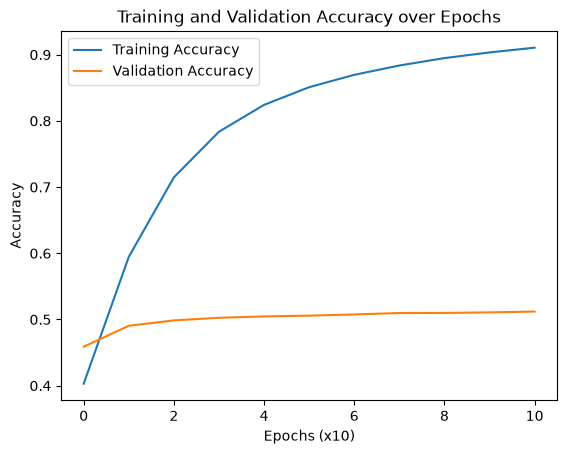

In [24]:
p1a_model = (nn.Sequential(nn.Linear(3072, 1024),
                      nn.ReLU(),
                      nn.Linear(1024, 256),
                      nn.ReLU(),
                      nn.Linear(256, 10))).to("mps")


p1a_optimizer = optim.Adam(p1a_model.parameters(), lr = 0.001)

p1a_train_loss, p1a_val_loss = train_test(p1a_model, p1a_optimizer, 100, n_cifar10)


In [25]:
numel_list = [p.numel() for p in p1a_model.parameters()]
sum(numel_list), numel_list

(3411722, [3145728, 1024, 262144, 256, 2560, 10])

Problem 1B

Training Epoch 1, Loss: 1.589978575706482
Training Epoch 10, Loss: 0.9935795068740845
Training Epoch 20, Loss: 0.5989823341369629
Training Epoch 30, Loss: 0.15781255066394806
Training Epoch 40, Loss: 0.07480720430612564
Training Epoch 50, Loss: 0.10626160353422165
Training Epoch 60, Loss: 0.23080064356327057
Training Epoch 70, Loss: 0.013963785022497177
Training Epoch 80, Loss: 0.02732536569237709
Training Epoch 90, Loss: 0.03171611577272415
Training Epoch 100, Loss: 0.20419079065322876


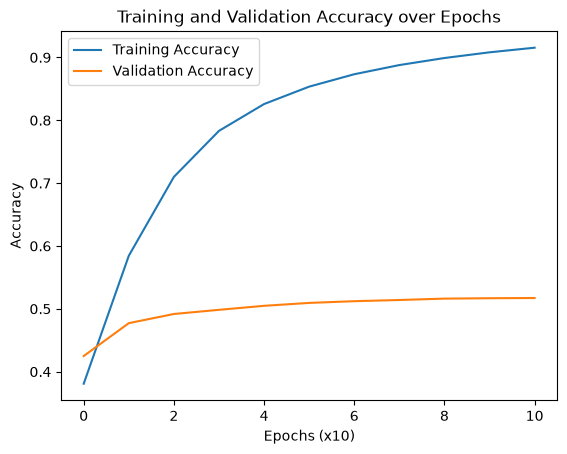

In [26]:
p1b_model = (nn.Sequential(nn.Linear(3072, 1024),
                      nn.ReLU(),
                      nn.Linear(1024, 341),
                      nn.ReLU(),
                      nn.Linear(341, 113),
                      nn.ReLU(),
                      nn.Linear(113, 38),
                      nn.ReLU(),
                      nn.Linear(38, 10))).to("mps")


p1b_optimizer = optim.Adam(p1b_model.parameters(), lr = 0.001)

p1b_train_loss, p1b_val_loss = train_test(p1b_model, p1b_optimizer, 100, n_cifar10)

In [27]:
numel_list = [p.numel() for p in p1b_model.parameters()]
sum(numel_list), numel_list

(3539645, [3145728, 1024, 349184, 341, 38533, 113, 4294, 38, 380, 10])

Problem 2A

Training Epoch 1, Loss: 1.8363593816757202
Training Epoch 10, Loss: 0.8869929909706116
Training Epoch 20, Loss: 0.37033700942993164
Training Epoch 30, Loss: 0.1649492084980011
Training Epoch 40, Loss: 0.023031756281852722
Training Epoch 50, Loss: 0.03427352383732796
Training Epoch 60, Loss: 0.026899762451648712
Training Epoch 70, Loss: 0.0028826782945543528
Training Epoch 80, Loss: 0.0035908729769289494
Training Epoch 90, Loss: 0.02349262684583664
Training Epoch 100, Loss: 0.06362666934728622


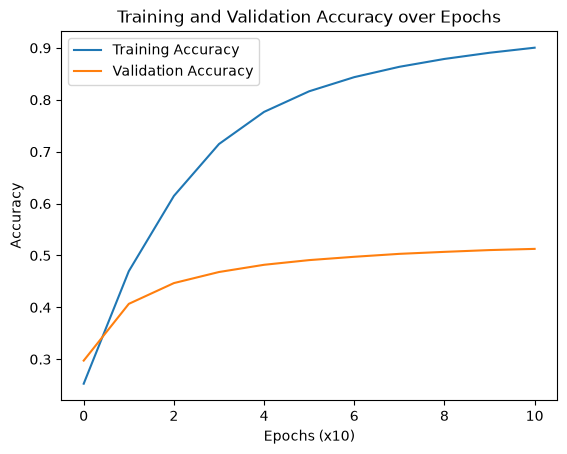

In [28]:
p2a_model = (nn.Sequential(nn.Linear(3072, 1920),
                      nn.ReLU(),
                      nn.Linear(1920, 1200),
                      nn.ReLU(),
                      nn.Linear(1200, 750),
                      nn.ReLU(),
                      nn.Linear(750, 341),
                      nn.ReLU(),
                      nn.Linear(341, 292),
                      nn.ReLU(),
                      nn.Linear(292, 183),
                      nn.ReLU(),
                      nn.Linear(183, 113),
                      nn.ReLU(),
                      nn.Linear(113, 71),
                      nn.ReLU(),
                      nn.Linear(71, 45),
                      nn.ReLU(),
                      nn.Linear(45, 38),
                      nn.ReLU(),
                      nn.Linear(38, 10))).to("mps")


p2a_optimizer = optim.Adam(p2a_model.parameters(), lr = 0.001)

p2a_train_loss, p2a_val_loss = train_test(p2a_model, p2a_optimizer, 100, n_cifar10)

In [29]:
numel_list = [p.numel() for p in p2a_model.parameters()]
sum(numel_list), numel_list

(9549948,
 [5898240,
  1920,
  2304000,
  1200,
  900000,
  750,
  255750,
  341,
  99572,
  292,
  53436,
  183,
  20679,
  113,
  8023,
  71,
  3195,
  45,
  1710,
  38,
  380,
  10])

Problem 2B

Training Epoch 1, Loss: 1.61909818649292
Training Epoch 10, Loss: 1.0775152444839478
Training Epoch 20, Loss: 0.4423563480377197
Training Epoch 30, Loss: 0.32968801259994507
Training Epoch 40, Loss: 0.22327443957328796
Training Epoch 50, Loss: 0.08465760946273804
Training Epoch 60, Loss: 0.1482452154159546
Training Epoch 70, Loss: 0.23885847628116608
Training Epoch 80, Loss: 0.2367183268070221
Training Epoch 90, Loss: 0.35328954458236694
Training Epoch 100, Loss: 0.15146727859973907


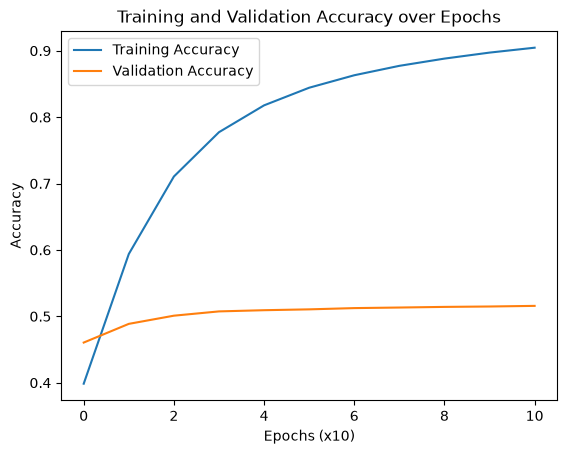

In [30]:
p2b1_model = (nn.Sequential(nn.Linear(3072, 2048),
                      nn.ReLU(),
                      nn.Linear(2048, 512),
                      nn.ReLU(),
                      nn.Linear(512, 10))).to("mps")


p2b1_optimizer = optim.Adam(p2b1_model.parameters(), lr = 0.001)

p2b1_train_loss, p2b1_val_loss = train_test(p2b1_model, p2b1_optimizer, 100, n_cifar10)

Training Epoch 1, Loss: 1.6497211456298828
Training Epoch 10, Loss: 0.8868303298950195
Training Epoch 20, Loss: 0.3919772803783417
Training Epoch 30, Loss: 0.2141597419977188
Training Epoch 40, Loss: 0.14691534638404846
Training Epoch 50, Loss: 0.07181712239980698
Training Epoch 60, Loss: 0.08698362857103348
Training Epoch 70, Loss: 0.059301428496837616
Training Epoch 80, Loss: 0.08211159706115723
Training Epoch 90, Loss: 0.03436170518398285
Training Epoch 100, Loss: 0.05332804471254349


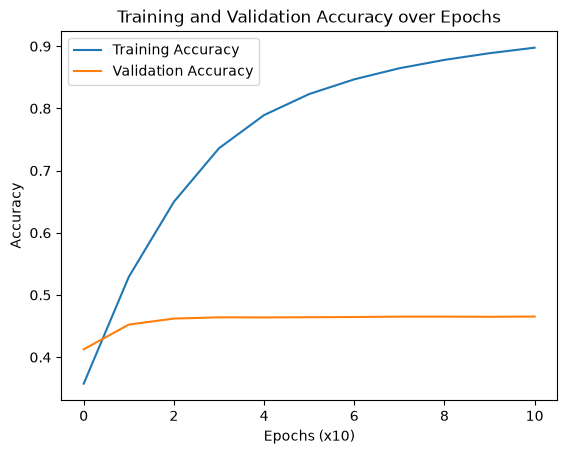

In [31]:
p2b2_model = (nn.Sequential(nn.Linear(3072, 1024),
                      nn.Sigmoid(),
                      nn.Linear(1024, 256),
                      nn.Sigmoid(),
                      nn.Linear(256, 10))).to("mps")


p2b2_optimizer = optim.Adam(p2b2_model.parameters(), lr = 0.001)

p2b2_train_loss, p2b2_val_loss = train_test(p2b2_model, p2b2_optimizer, 100, n_cifar10)

Training Epoch 1, Loss: 1.668261170387268
Training Epoch 10, Loss: 1.327465295791626
Training Epoch 20, Loss: 0.8879052996635437
Training Epoch 30, Loss: 0.4012565612792969
Training Epoch 40, Loss: 0.3672199249267578
Training Epoch 50, Loss: 0.4205029606819153
Training Epoch 60, Loss: 0.1595344841480255
Training Epoch 70, Loss: 0.3247032165527344
Training Epoch 80, Loss: 0.3067449927330017
Training Epoch 90, Loss: 0.2928232252597809
Training Epoch 100, Loss: 0.2643434703350067


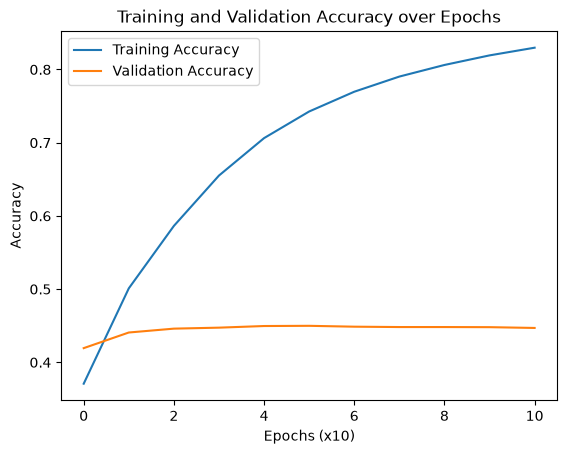

In [32]:
p2b3_model = (nn.Sequential(nn.Linear(3072, 1024),
                      nn.Tanh(),
                      nn.Linear(1024, 256),
                      nn.Tanh(),
                      nn.Linear(256, 10))).to("mps")


p2b3_optimizer = optim.Adam(p2b3_model.parameters(), lr = 0.001)

p2b3_train_loss, p2b3_val_loss = train_test(p2b3_model, p2b3_optimizer, 100, n_cifar10)

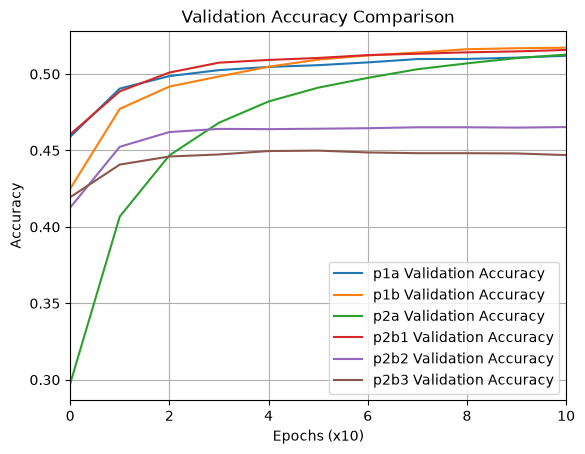

In [33]:
plt.grid()
plt.plot(p1a_val_loss, label='p1a Validation Accuracy')
plt.plot(p1b_val_loss, label='p1b Validation Accuracy')
plt.plot(p2a_val_loss, label='p2a Validation Accuracy')
plt.plot(p2b1_val_loss, label='p2b1 Validation Accuracy')
plt.plot(p2b2_val_loss, label='p2b2 Validation Accuracy')
plt.plot(p2b3_val_loss, label='p2b3 Validation Accuracy')
plt.xlim(0, 10)
plt.xlabel('Epochs (x10)')
plt.ylabel('Accuracy')
plt.title('Validation Accuracy Comparison')
plt.legend()